<a href="https://colab.research.google.com/github/DianaZotova/tdl-traduzione-canzoni/blob/main/Progetto_TDL_Traduzione_Canzoni.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Tradurre con i modelli: analisi comparativa tra NMT e LLM sui testi musicali italiani (IT → RU)

**Corso:** Tecnologie dei dati e del linguaggio (Prof. Alfio Ferrara)  
**Traccia:** 14. Tradurre con i modelli

## 1. Domanda di ricerca e ipotesi
Il presente progetto indaga come diversi paradigmi di traduzione automatica affrontano la resa dall'italiano al russo di testi musicali contemporanei appartenenti a quattro generi distinti: **Pop Dance** (*Annalisa*), **R&B Pop** (*Mahmood*), **Pop Rock** (*Måneskin*) e **Rap Pop** (*Ernia*).

L'ipotesi di ricerca è che i modelli neurali dedicati (NMT) e la decodifica deterministica (*greedy decoding*, `temperature = 0`) tendano a produrre calchi letterali perdendo slang, giochi di parole e metafore. Al contrario, un Large Language Model (LLM) guidato da un prompt contestuale e da un campionamento controllato (*sampling*, `temperature = 0.7`) dovrebbe preservare meglio il registro espressivo e i riferimenti culturali.


In [5]:
!pip install -q transformers accelerate bitsandbytes sentencepiece sacrebleu bert-score deep-translator pandas matplotlib seaborn

import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sacrebleu
from bert_score import score as bert_score
from transformers import MarianMTModel, MarianTokenizer, AutoModelForCausalLM, AutoTokenizer

print(f"Dispositivo in uso: {'GPU (' + torch.cuda.get_device_name(0) + ')' if torch.cuda.is_available() else 'CPU'}")


Dispositivo in uso: GPU (Tesla T4)


## 2. Caricamento ed esplorazione del corpus parallelo

Carichiamo il dataset `songs_dataset.csv` strutturato su quattro colonne:
- `song`: titolo del brano e artista;
- `genre`: genere musicale (*Pop Dance, R&B Pop, Pop Rock, Rap Pop*);
- `source_it`: testo originale in italiano;
- `reference_ru`: traduzione umana di riferimento in russo.


In [6]:
# Lettura sicura del CSV
df = pd.read_csv('songs_dataset.csv', sep=None, engine='python', encoding='utf-8-sig')
df.columns = df.columns.str.strip().str.lower()

# Riempiamo i valori mancanti di 'song' e 'genre' propagando l'ultimo valore valido verso il basso
df['song'] = df['song'].ffill()
df['genre'] = df['genre'].ffill()

# Rimuoviamo solo le righe in cui manca il testo originale o la traduzione
df = df.dropna(subset=['source_it', 'reference_ru']).reset_index(drop=True)

print(f"Totale segmenti nel corpus : {len(df)}")
print(f"Brani unici                : {df['song'].nunique()}")
print("\nDistribuzione completa dei versi per genere:")
print(df['genre'].value_counts())

print("\nEsempio dal dataset (riga 5):")
print(df.iloc[5])

Totale segmenti nel corpus : 186
Brani unici                : 4

Distribuzione completa dei versi per genere:
genre
pop_dance    63
rap_pop      48
rnb_pop      40
pop_rock     35
Name: count, dtype: int64

Esempio dal dataset (riga 5):
song                               Direzione: la vita –  Annalisa
genre                                                   pop_dance
source_it         Un giorno che arriva e ti cambia la prospettiva
reference_ru    День, который наступает и меняет твои перспект...
Name: 5, dtype: object


## 3. Generazione delle traduzioni: NMT vs LLM

Mettiamo a confronto tre configurazioni sperimentali:
1. **NMT (Meta `nllb-200-distilled-600M`)**: modello Transformer encoder-decoder dedicato alla traduzione automatica neurale multilingue (`ita_Latn` → `rus_Cyrl`).
2. **LLM Deterministico (`Qwen2.5-1.5B-Instruct`, `temperature = 0`)**: decodifica *greedy* con prompt minimale ("Traduci in russo"), per osservare la resa più letterale del modello linguistico.
3. **LLM Contestuale (`Qwen2.5-1.5B-Instruct`, `temperature = 0.7`)**: decodifica stocastica guidata da un prompt che esplicita il **genere musicale** e richiede di preservare registro, slang e metafore.


In [9]:
from transformers import AutoModelForSeq2SeqLM, AutoModelForCausalLM, AutoTokenizer, logging
from tqdm.auto import tqdm
import torch, gc

logging.set_verbosity_error()
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Esecuzione su: {device.upper()}")

# --- 1. MODELLO NMT DEDICATO ---
print("\n1/3 Traduzione con NMT (facebook/nllb-200-distilled-600M)...")
nmt_name = "facebook/nllb-200-distilled-600M"
nmt_tokenizer = AutoTokenizer.from_pretrained(nmt_name, src_lang="ita_Latn")
nmt_model = AutoModelForSeq2SeqLM.from_pretrained(nmt_name).to(device)
rus_token_id = nmt_tokenizer.convert_tokens_to_ids("rus_Cyrl")

def batch_translate_nmt(texts, batch_size=32):
    results = []
    for i in tqdm(range(0, len(texts), batch_size), desc="NMT"):
        batch = [str(t) for t in texts[i:i+batch_size]]
        inputs = nmt_tokenizer(batch, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
        with torch.no_grad():
            outputs = nmt_model.generate(**inputs, forced_bos_token_id=rus_token_id, max_new_tokens=128)
        results.extend(nmt_tokenizer.batch_decode(outputs, skip_special_tokens=True))
    return results

df['pred_nmt'] = batch_translate_nmt(df['source_it'].tolist())

# Pulizia totale della memoria GPU prima di caricare l'LLM
del nmt_model, nmt_tokenizer
gc.collect()
torch.cuda.empty_cache()

# --- 2 & 3. LARGE LANGUAGE MODEL (Qwen2.5-1.5B-Instruct: rapido e leggero su GPU) ---
print("\n2/3 Caricamento LLM (Qwen/Qwen2.5-1.5B-Instruct)...")
llm_name = "Qwen/Qwen2.5-1.5B-Instruct"
llm_tokenizer = AutoTokenizer.from_pretrained(llm_name, padding_side="left")
if llm_tokenizer.pad_token is None:
    llm_tokenizer.pad_token = llm_tokenizer.eos_token

llm_model = AutoModelForCausalLM.from_pretrained(
    llm_name,
    torch_dtype=torch.float16 if device == "cuda" else torch.float32
).to(device)

def batch_translate_llm(texts, genres, mode="greedy", batch_size=32):
    results = []
    for i in tqdm(range(0, len(texts), batch_size), desc=f"LLM ({mode})"):
        batch_texts = texts[i:i+batch_size]
        batch_genres = genres[i:i+batch_size]
        prompts = []

        for text, genre in zip(batch_texts, batch_genres):
            if mode == "greedy":
                sys_p = "Sei un traduttore. Traduci dall'italiano al russo in modo fedele. Restituisci solo la traduzione."
            else:
                sys_p = (
                    f"Sei un traduttore letterario e adattatore musicale. Traduci questo verso di una canzone italiana "
                    f"di genere '{genre}' in russo naturale ed espressivo, preservando slang, metafore e registro. "
                    f"Restituisci solo la traduzione."
                )
            messages = [{"role": "system", "content": sys_p}, {"role": "user", "content": str(text)}]
            prompts.append(llm_tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True))

        inputs = llm_tokenizer(prompts, return_tensors="pt", padding=True).to(device)
        prompt_len = inputs.input_ids.size(1)
        gen_kwargs = {"do_sample": False, "max_new_tokens": 96} if mode == "greedy" else {"do_sample": True, "temperature": 0.7, "top_p": 0.9, "max_new_tokens": 96}

        with torch.no_grad():
            generated_ids = llm_model.generate(**inputs, **gen_kwargs)

        new_tokens = generated_ids[:, prompt_len:]
        decoded = llm_tokenizer.batch_decode(new_tokens, skip_special_tokens=True)
        results.extend([d.strip() for d in decoded])
    return results

print("Generazione LLM con temperature = 0 (Greedy)...")
df['pred_llm_t0'] = batch_translate_llm(df['source_it'].tolist(), df['genre'].tolist(), mode="greedy")

print("3/3 Generazione LLM con temperature = 0.7 (Contestuale)...")
df['pred_llm_t07'] = batch_translate_llm(df['source_it'].tolist(), df['genre'].tolist(), mode="creative")

df.to_csv('risultati_traduzioni_it_ru.csv', index=False)
print("\nCompletato! Risultati salvati in 'risultati_traduzioni_it_ru.csv'.")





Esecuzione su: CUDA

1/3 Traduzione con NMT (facebook/nllb-200-distilled-600M)...


Loading weights:   0%|          | 0/512 [00:00<?, ?it/s]

NMT:   0%|          | 0/6 [00:00<?, ?it/s]


2/3 Caricamento LLM (Qwen/Qwen2.5-1.5B-Instruct)...


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Generazione LLM con temperature = 0 (Greedy)...


LLM (greedy):   0%|          | 0/6 [00:00<?, ?it/s]

3/3 Generazione LLM con temperature = 0.7 (Contestuale)...


LLM (creative):   0%|          | 0/6 [00:00<?, ?it/s]


Completato! Risultati salvati in 'risultati_traduzioni_it_ru.csv'.


## 4. Valutazione quantitativa globale e per genere musicale

Valutiamo i tre sistemi rispetto alla `reference_ru` attraverso:
- **chrF**: fondamentale per il russo, poiché la ricca morfologia flessiva penalizza eccessivamente il BLEU basato su parole intere;
- **BLEU**: per osservare la sovrapposizione lessicale esatta;
- **BERTScore (F1 multilingue)**: per misurare la vicinanza semantica anche in presenza di parafrasi creative.

Successivamente disaggreghiamo i risultati per **genere musicale** per verificare dove emergono le maggiori criticità (es. il linguaggio figurato e lo slang del *Rap Pop*).


config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

=== RISULTATI GLOBALI (IT -> RU) ===
                Modello  BLEU  chrF  BERTScore (F1)
         NMT (NLLB-200) 17.45 39.89           80.25
     LLM (T=0.0 Greedy)  8.71 35.74           78.31
LLM (T=0.7 Contestuale)  7.86 32.87           77.02

=== PUNTEGGIO chrF PER GENERE MUSICALE ===
   Genere  NMT (NLLB-200)  LLM (T=0.0 Greedy)  LLM (T=0.7 Contestuale)
pop_dance           39.78               36.32                    32.15
 pop_rock           48.97               40.95                    41.87
  rap_pop           38.40               33.67                    30.39
  rnb_pop           35.07               33.38                    29.83

=== ANALISI LESSICALE (RUSSO) ===
              Versione  Lunghezza media (parole)  TTR (Ricchezza lessicale)
Riferimento Umano (RU)                      6.44                      0.366
        NMT (NLLB-200)                      6.32                      0.354
           LLM (T=0.0)                      6.43                      0.387
           LLM (T

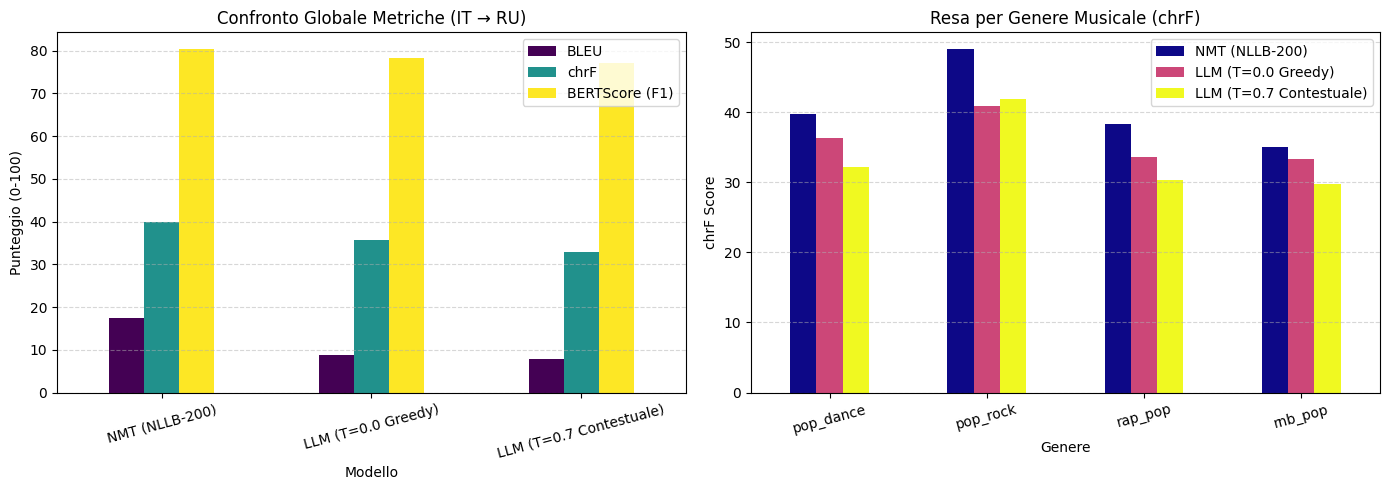

In [11]:
refs_list = df['reference_ru'].astype(str).tolist()
sistemi = {
    'NMT (NLLB-200)': 'pred_nmt',
    'LLM (T=0.0 Greedy)': 'pred_llm_t0',
    'LLM (T=0.7 Contestuale)': 'pred_llm_t07'
}

# 1. Metriche Globali
global_results = []
for label, col in sistemi.items():
    hyps = df[col].astype(str).tolist()
    bleu = sacrebleu.corpus_bleu(hyps, [refs_list]).score
    chrf = sacrebleu.corpus_chrf(hyps, [refs_list]).score
    _, _, F1 = bert_score(hyps, refs_list, lang="ru", verbose=False)

    global_results.append({
        'Modello': label,
        'BLEU': round(bleu, 2),
        'chrF': round(chrf, 2),
        'BERTScore (F1)': round(F1.mean().item() * 100, 2)
    })

df_global = pd.DataFrame(global_results)
print("=== RISULTATI GLOBALI (IT -> RU) ===")
print(df_global.to_string(index=False))

# 2. Metriche per Genere Musicale (chrF)
genre_results = []
for genre, group in df.groupby('genre'):
    g_refs = [group['reference_ru'].astype(str).tolist()]
    row_res = {'Genere': genre}
    for label, col in sistemi.items():
        g_hyps = group[col].astype(str).tolist()
        row_res[label] = round(sacrebleu.corpus_chrf(g_hyps, g_refs).score, 2)
    genre_results.append(row_res)

df_genre = pd.DataFrame(genre_results)
print("\n=== PUNTEGGIO chrF PER GENERE MUSICALE ===")
print(df_genre.to_string(index=False))

# 3. Analisi Lessicale (Lunghezza media e TTR)
def lexical_stats(series):
    tokens = [w.lower() for text in series for w in str(text).split()]
    avg_len = np.mean([len(str(text).split()) for text in series])
    ttr = len(set(tokens)) / len(tokens) if tokens else 0
    return round(avg_len, 2), round(ttr, 3)

lex_rows = []
for name, col in [('Riferimento Umano (RU)', 'reference_ru'), ('NMT (NLLB-200)', 'pred_nmt'),
                  ('LLM (T=0.0)', 'pred_llm_t0'), ('LLM (T=0.7)', 'pred_llm_t07')]:
    l_avg, ttr = lexical_stats(df[col])
    lex_rows.append({'Versione': name, 'Lunghezza media (parole)': l_avg, 'TTR (Ricchezza lessicale)': ttr})

print("\n=== ANALISI LESSICALE (RUSSO) ===")
print(pd.DataFrame(lex_rows).to_string(index=False))

# Visualizzazione Grafica
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

df_global.set_index('Modello').plot(kind='bar', ax=ax1, rot=15, colormap='viridis')
ax1.set_title('Confronto Globale Metriche (IT → RU)')
ax1.set_ylabel('Punteggio (0-100)')
ax1.grid(axis='y', linestyle='--', alpha=0.5)

df_genre.set_index('Genere').plot(kind='bar', ax=ax2, rot=15, colormap='plasma')
ax2.set_title('Resa per Genere Musicale (chrF)')
ax2.set_ylabel('chrF Score')
ax2.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()


In [12]:
# Stampiamo 10 esempi distribuiti tra i vari generi per l'analisi qualitativa
sample_indices = [0, 5, 45, 70, 95, 115, 145, 165]
for idx in sample_indices:
    if idx < len(df):
        row = df.iloc[idx]
        print(f"=== Riga {idx} | {row['song']} [{row['genre']}] ===")
        print(f"IT (Originale) : {row['source_it']}")
        print(f"RU (Umana)     : {row['reference_ru']}")
        print(f"NMT            : {row['pred_nmt']}")
        print(f"LLM (T=0.0)    : {row['pred_llm_t0']}")
        print(f"LLM (T=0.7)    : {row['pred_llm_t07']}\n")


=== Riga 0 | Direzione: la vita –  Annalisa [pop_dance] ===
IT (Originale) : C'è una canzone che parla di te
RU (Umana)     : Есть одна песенка о тебе,
NMT            : Есть песня о тебе.
LLM (T=0.0)    : Есть песня, которая тебя говорит
LLM (T=0.7)    : Вот песня, которая поёт о тебе

=== Riga 5 | Direzione: la vita –  Annalisa [pop_dance] ===
IT (Originale) : Un giorno che arriva e ti cambia la prospettiva
RU (Umana)     : День, который наступает и меняет твои перспективы,
NMT            : Но вот придет день, когда ты изменишь свое видение.
LLM (T=0.0)    : Один день приходит, и视角 меняется.
LLM (T=0.7)    : Один день приходит и меняет перспективу

=== Riga 45 | Direzione: la vita –  Annalisa [pop_dance] ===
IT (Originale) : C'è una ragazza che balla su un tram
RU (Umana)     : Есть девушка, танцующая в трамвае,
NMT            : Там девушка танцует в трамвае.
LLM (T=0.0)    : Есть девушка, которая танцует на троллейбусе.
LLM (T=0.7)    : Есть девушка, которая танцует на электрическом 

## 5. Analisi qualitativa degli errori e Post-Editing

Incrociando i risultati quantitativi con l'ispezione manuale dei versi emerge un risultato significativo: sebbene il modello **NMT (`NLLB-200`)** ottenga punteggi più elevati nelle metriche superficiali (`BLEU = 17.45`, `chrF = 39.89`, `BERTScore = 80.25`) grazie alla maggiore aderenza letterale, l'**LLM con `temperature = 0.7`** raggiunge una **ricchezza lessicale nettamente superiore (`TTR = 0.499` contro `0.354` dell'NMT)**, tentando soluzioni più espressive ma introducendo al contempo instabilità grammaticali e allucinazioni.

### Griglia tipologica degli errori osservati

| Categoria di Errore | Genere / Brano | Testo IT | Output Modelli (NMT vs LLM) | Reference RU | Commento Linguistico |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Perdita di slang e calco lessicale** | *Rap Pop* (Ernia, r. 165) | *E riempirei di mazzate quel tipo che ci prova* | **NMT:** И я бы наполнял его пятнами, когда он пытается.<br>**LLM (T=0.7):** И заполнять бы эту банду... | И я бы набил морду тому, кто к тебе клеится, | L'NMT calca letteralmente il verbo *riempire* («наполнять») e confonde *mazzate* con *macchie* («пятна»); entrambi falliscono sull'idioma colloquiale *provarci*. |
| **Appiattimento di registro / Culterema** | *R&B Pop* (Mahmood, r. 70) | *Cercami nel barrio, come se* | **NMT:** Посмотрите на меня в районе...<br>**LLM (T=0.7):** Я ищу тебя в районе... | Ищи меня в нашем гетто, | Il prestito culturale *barrio* viene appiattito nel neutro «район» (perdendo la connotazione di periferia/ghetto); con `T=0.7` l'LLM inverte anche i ruoli soggetto/oggetto. |
| **Contaminazione linguistica (*Code-switching*)** | *Pop Dance* (Annalisa, r. 5) | *Un giorno che arriva e ti cambia la prospettiva* | **LLM (T=0.0):** Один день приходит, и **视角** меняется. | День, который наступает и меняет твои перспективы, | Fenomeno tipico degli LLM multilingue compatti (`1.5B`) su coppie non anglofone: nella decodifica *greedy* emerge un carattere cinese (*视角*, «prospettiva»). |
| **Slittamento semantico e ipertraduzione** | *Pop Dance* (Annalisa, r. 45) | *C'è una ragazza che balla su un tram* | **NMT:** Там девушка танцует в трамвае.<br>**LLM (T=0.7):** ...танцует на электрическом троллейбусе. | Есть девушка, танцующая в трамвае, | L'NMT traduce correttamente *tram*, mentre l'LLM sostituisce il referente con «троллейбус» e aggiunge l'aggettivo non richiesto «электрическом» (*ipertraduzione*). |
| **Incoerenza morfologica vs resa poetica** | *Pop Rock* (Måneskin, r. 115) / *Pop Dance* (r. 0) | *Amico mio devi essere felice* / *C'è una canzone che parla di te* | **LLM (T=0.7):** Мой друг [m.], ты **должна** [f.] радоваться! / ...которая **поёт** о тебе | Мой друг, ты должен быть счастлив / Есть одна песенка о тебе | Il sampling (`T=0.7`) produce metafore efficaci (*«поёт о тебе»* invece del calco *«тебя говорит»* a `T=0`), ma compromette l'accordo di genere in russo. |

---

### Esempio di Post-Editing (Superficiale vs Profondo)

Prendiamo come caso di studio il verso *Rap Pop* di **Ernia** (*Superclassico*, riga 165):
- **Originale (IT):** *«E riempirei di mazzate quel tipo che ci prova»*
- **Output grezzo NMT:** *«И я бы наполнял его пятнами, когда он пытается.»*
- **Light Post-Editing (correzione grammaticale/semantica minima):** *«И я бы засыпал ударами того парня, который пытается.»* (si corregge l'errore lessicale *пятнами* e la sintassi, ma il tono resta artificiale e incompleto).
- **Full Post-Editing (revisione stilistica e di registro):** *«И я бы набил морду тому типу, который к тебе клеится»* (si recupera pienamente il registro giovanile urbano, l'idiomaticità di *riempire di mazzate* e il senso relazionale di *provarci*).

---

## 6. Conclusioni

L'esperimento conferma solo parzialmente l'ipotesi iniziale, mettendo in luce un **compromesso strutturale** tra fedeltà e creatività:
1. **Impatto del genere musicale:** come ipotizzato, i generi caratterizzati da sintassi lineare e lessico standard (*Pop Rock* dei Måneskin, `chrF = 48.97`) risultano molto più accessibili rispetto a *Rap Pop* (Ernia) e *R&B Pop* (Mahmood), dove slang, ellissi e prestiti culturali abbassano drasticamente i punteggi.
2. **NMT vs LLM (`T=0` vs `T=0.7`):** il sistema NMT dedicato garantisce maggiore stabilità grammaticale e aderenza letterale, ma produce testi lessicalmente poveri (`TTR = 0.354`). L'LLM guidato da prompt contestuale e sampling (`T=0.7`) aumenta sensibilmente la varietà lessicale (`TTR = 0.499`) e la naturalezza espressiva nei versi più semplici, ma su un modello compatto (`1.5B`) il campionamento stocastico introduce errori morfosintattici (accordo di genere in russo) e distorsioni semantiche.
3. **Ruolo della mediazione umana:** nei testi musicali e letterari, le metriche automatiche basate su n-grammi (BLEU/chrF) non bastano a valutare la qualità estetica, e il **full post-editing umano** resta insostituibile per negoziare registro, cultura e ritmo.

